# Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine
## Diyabet Riski Tahmini (Sağlık)

Bu not defteri 7 aşamayı sırayla izler. Veri seti: Pima Indians Diabetes (768 kişi, 8 özellik).

**Çalıştırmadan önce:** Aşağıdaki hücre veri setini internetten indirir. Colab'da doğrudan çalışır.

## Aşama 1: Problem Tanımı ve Proje Planı

**Proje Tanım Formu**

| Alan | Değer |
|---|---|
| Problem cümlesi | Glukoz, BMI, yaş, insülin, kan basıncı gibi bilgilerden kişinin diyabet olup olmadığını tahmin et. |
| Hedef değişken | diyabet (0 = yok, 1 = var) |
| Problem türü | Sınıflandırma |

**Gerekçe:** Diyabet erken fark edilmezse ciddi komplikasyonlara yol açar. Basit bir ölçüm setinden risk tahmini yapan bir araç, sağlık çalışanlarına ve bireylere "doktor kontrolü gerekli mi?" sorusunda ilk filtre olarak yardımcı olur. Bu proje bir tanı aracı değil, öğrenme amaçlı bir risk tahmin modelidir.

## Aşama 2: Veri Toplama ve Hazırlama

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolonlar = ["hamilelik_sayisi", "glukoz", "kan_basinci", "cilt_kalinligi",
            "insulin", "bmi", "soy_agaci_fonksiyonu", "yas", "diyabet"]

df = pd.read_csv(url, header=None, names=kolonlar)
df.to_csv("diyabet_ham.csv", index=False)   # CSV olarak kaydet
df.head()

,hamilelik_sayisi,glukoz,kan_basinci,cilt_kalinligi,insulin,bmi,soy_agaci_fonksiyonu,yas,diyabet
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Veri Sözlüğü**

| Sütun | Tip | Anlam |
|---|---|---|
| hamilelik_sayisi | Sayısal | Hamilelik sayısı |
| glukoz | Sayısal | Oral glukoz tolerans testinde 2 saatlik plazma glukozu (mg/dL) |
| kan_basinci | Sayısal | Diyastolik kan basıncı (mm Hg) |
| cilt_kalinligi | Sayısal | Triseps deri kıvrım kalınlığı (mm) |
| insulin | Sayısal | 2 saatlik serum insülini (mu U/ml) |
| bmi | Sayısal | Beden kitle indeksi (kg/m2) |
| soy_agaci_fonksiyonu | Sayısal | Ailede diyabet öyküsünü özetleyen skor |
| yas | Sayısal | Yaş (yıl) |
| diyabet | Kategorik (0/1) | Hedef: 1 diyabet var, 0 yok |

In [2]:
# Eksik veri kontrolü
print("isnull toplamı:", df.isnull().sum().sum())

# Bu sütunlarda 0 değeri fiziksel olarak mümkün değil, yani eksik veri demek
sifir_sutunlar = ["glukoz", "kan_basinci", "cilt_kalinligi", "insulin", "bmi"]
print("Sıfır sayıları:")
print((df[sifir_sutunlar] == 0).sum())

isnull toplamı: 0
Sıfır sayıları:
glukoz              5
kan_basinci        35
cilt_kalinligi    227
insulin           374
bmi                11
dtype: int64


In [3]:
# 0 değerlerini NaN yap
df[sifir_sutunlar] = df[sifir_sutunlar].replace(0, np.nan)
print("dropna ile kalacak satır:", df.dropna().shape[0], "/", df.shape[0])

# dropna çok veri kaybettirir, bu yüzden medyan ile dolduruyoruz (fillna)
for c in sifir_sutunlar:
    df[c] = df[c].fillna(df[c].median())

print("Kalan eksik değer:", df.isnull().sum().sum())
df.to_csv("diyabet_temiz.csv", index=False)

dropna ile kalacak satır: 392 / 768
Kalan eksik değer: 0


**Temizleme açıklaması:** isnull hiç eksik göstermedi, ama glukoz, kan basıncı, cilt kalınlığı, insülin ve BMI sütunlarında 0 değerleri vardı (insülinde 374 satır). Bunlar gerçek ölçüm olamaz. 0 değerleri NaN yapıldı. dropna kullanılırsa yalnızca 392 satır kalırdı, bu yüzden eksikler sütun medyanı ile dolduruldu.

## Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [4]:
print("shape:", df.shape)
display(df.describe().round(2))
print(df["diyabet"].value_counts())

shape: (768, 9)


,hamilelik_sayisi,glukoz,kan_basinci,cilt_kalinligi,insulin,bmi,soy_agaci_fonksiyonu,yas,diyabet
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,121.66,72.39,29.11,140.67,32.46,0.47,33.24,0.35
std,3.37,30.44,12.10,8.79,86.38,6.88,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.75,64.00,25.00,121.50,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,29.00,125.00,32.30,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


diyabet
0    500
1    268
Name: count, dtype: int64


In [5]:
# Hedefe göre ortalama farkları
df.groupby("diyabet").mean().round(2)

,hamilelik_sayisi,glukoz,kan_basinci,cilt_kalinligi,insulin,bmi,soy_agaci_fonksiyonu,yas
diyabet,,,,,,,,
0,3.30,110.68,70.92,27.73,127.79,30.89,0.43,31.19
1,4.87,142.13,75.12,31.69,164.70,35.38,0.55,37.07


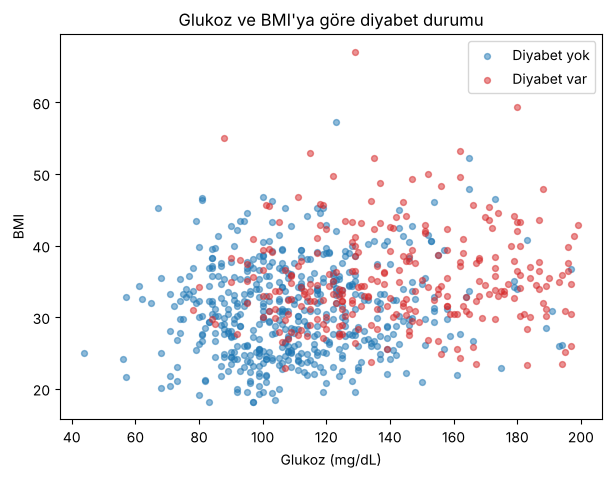

In [6]:
# Grafik 1: dağılım (scatter)
plt.figure(figsize=(7, 5))
for d, renk, ad in [(0, "tab:blue", "Diyabet yok"), (1, "tab:red", "Diyabet var")]:
    s = df[df["diyabet"] == d]
    plt.scatter(s["glukoz"], s["bmi"], c=renk, alpha=0.5, label=ad, s=18)
plt.title("Glukoz ve BMI'ya göre diyabet durumu")
plt.xlabel("Glukoz (mg/dL)")
plt.ylabel("BMI")
plt.legend()
plt.show()

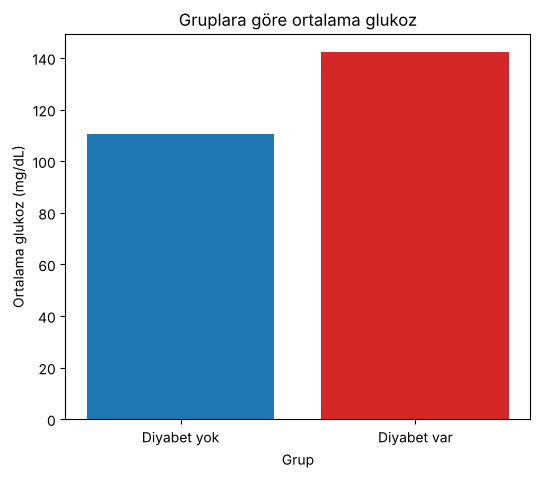

In [7]:
# Grafik 2: çubuk (bar)
ort = df.groupby("diyabet")["glukoz"].mean()
plt.figure(figsize=(6, 5))
plt.bar(["Diyabet yok", "Diyabet var"], ort.values, color=["tab:blue", "tab:red"])
plt.title("Gruplara göre ortalama glukoz")
plt.xlabel("Grup")
plt.ylabel("Ortalama glukoz (mg/dL)")
plt.show()

In [8]:
# Hedefle korelasyon
df.corr()["diyabet"].drop("diyabet").sort_values(ascending=False).round(3)

glukoz                  0.493
bmi                     0.312
yas                     0.238
hamilelik_sayisi        0.222
cilt_kalinligi          0.215
insulin                 0.204
soy_agaci_fonksiyonu    0.174
kan_basinci             0.166
Name: diyabet, dtype: float64

**Keşif Bulguları**
1. Veride 768 kişi var, 500'ü diyabetsiz, 268'i diyabetli. Sınıflar dengesiz (yaklaşık %65 / %35).
2. Glukoz en belirleyici özellik: diyabetlilerde ortalama 142, diyabetsizlerde 111 mg/dL. Hedefle korelasyonu 0.49.
3. BMI ikinci sırada: diyabetlilerde ortalama 35.4, diyabetsizlerde 30.9.
4. Diyabetliler ortalama olarak daha yaşlı (37 yıla karşı 31 yıl) ve daha fazla hamilelik geçirmiş.
5. Scatter grafikte yüksek glukoz bölgesi neredeyse tamamen kırmızı noktalardan oluşuyor.

## Aşama 4: Model Kurma ve Eğitme

In [9]:
X = df.drop(columns="diyabet")   # özellikler
y = df["diyabet"]                # hedef

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

X_train: (614, 8) X_test: (154, 8)
y_train: (614,) y_test: (154,)


In [10]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

**Model seçim gerekçesi:** Hedef 0/1 olduğu için sınıflandırma modeli gerekir. DecisionTreeClassifier hem kurması kolay hem de nasıl karar verdiğini açıklamak kolay bir model. Ağacın derinliğini 4 ile sınırladık, çünkü sınırsız ağaç eğitim verisini ezberliyor (aşağıda gösterilecek).

## Aşama 5: Tahmin ve Değerlendirme

In [11]:
tahmin = model.predict(X_test)
print("Test doğruluğu:", round(accuracy_score(y_test, tahmin), 3))
print("Eğitim doğruluğu:", round(model.score(X_train, y_train), 3))
print("Karışıklık matrisi:")
print(confusion_matrix(y_test, tahmin))

Test doğruluğu: 0.786
Eğitim doğruluğu: 0.795
Karışıklık matrisi:
[[84 16]
 [17 37]]


In [12]:
# Aşırı öğrenme kontrolü: derinlik sınırı olmayan ağaç
tam = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Sınırsız ağaç eğitim:", round(tam.score(X_train, y_train), 3))
print("Sınırsız ağaç test:", round(tam.score(X_test, y_test), 3))

Sınırsız ağaç eğitim: 1.0
Sınırsız ağaç test: 0.682


In [13]:
# Özellik önemi
pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).round(3)

glukoz                  0.670
bmi                     0.168
yas                     0.119
insulin                 0.043
cilt_kalinligi          0.000
kan_basinci             0.000
hamilelik_sayisi        0.000
soy_agaci_fonksiyonu    0.000
dtype: float64

In [14]:
# 3 yeni örnek için tahmin tablosu
yeni = pd.DataFrame([
    [2, 95, 70, 25, 80, 24.0, 0.25, 25],
    [5, 150, 80, 32, 150, 33.0, 0.60, 45],
    [8, 185, 88, 30, 200, 36.5, 0.90, 52],
], columns=X.columns)
yeni["tahmin"] = model.predict(yeni[X.columns])
yeni["risk_olasiligi"] = model.predict_proba(yeni[X.columns])[:, 1].round(2)
yeni

,hamilelik_sayisi,glukoz,kan_basinci,cilt_kalinligi,insulin,bmi,soy_agaci_fonksiyonu,yas,tahmin,risk_olasiligi
0,2,95,70,25,80,24.0,0.25,25,0,0.02
1,5,150,80,32,150,33.0,0.60,45,1,0.56
2,8,185,88,30,200,36.5,0.90,52,1,0.89


**Değerlendirme Notu**
- Test doğruluğu yaklaşık %78.6, eğitim doğruluğu yaklaşık %79.5. İkisi birbirine yakın, yani sınırlı ağaçta aşırı öğrenme yok.
- Sınırsız ağaç eğitimde %100, testte yaklaşık %68 aldı. Bu klasik aşırı öğrenme örneği, derinlik sınırının neden önemli olduğunu gösteriyor.
- Karışıklık matrisine göre model 54 diyabetli kişinin 37'sini yakaladı, 17'sini kaçırdı. Sağlıkta kaçırılan hasta pahalı bir hata olduğu için model tanı koymak için güvenilir değil.
- Zayıf yönler: küçük veri seti (768 satır), insülinde çok fazla eksik değer, tek bir popülasyon (Pima kadınları), sınıf dengesizliği. İyileştirme için RandomForest, çapraz doğrulama ve doğruluk yerine recall ölçümü denenebilir.

## Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

In [15]:
def tahmin_et(hamilelik, glukoz, kan_basinci, cilt, insulin, bmi, soy, yas):
    satir = pd.DataFrame([[hamilelik, glukoz, kan_basinci, cilt, insulin, bmi, soy, yas]],
                         columns=X.columns)
    sonuc = model.predict(satir)[0]
    olasilik = model.predict_proba(satir)[0][1]
    durum = "diyabet riski YÜKSEK" if sonuc == 1 else "diyabet riski DÜŞÜK"
    return f"Tahmin: {durum} (risk olasılığı %{olasilik * 100:.0f})"

print(tahmin_et(2, 95, 70, 25, 80, 24.0, 0.25, 25))
print(tahmin_et(8, 185, 88, 30, 200, 36.5, 0.90, 52))

Tahmin: diyabet riski DÜŞÜK (risk olasılığı %2)
Tahmin: diyabet riski YÜKSEK (risk olasılığı %89)


In [ ]:
# Kullanıcıdan girdi alan sürüm (Colab'da hücreyi çalıştırıp değerleri gir)
print("Kişi bilgilerini gir:")
h = int(input("Hamilelik sayısı: "))
g = float(input("Glukoz: "))
k = float(input("Kan basıncı: "))
c = float(input("Cilt kalınlığı: "))
i = float(input("İnsülin: "))
b = float(input("BMI: "))
s = float(input("Soy ağacı skoru (örn. 0.5): "))
a = int(input("Yaş: "))
print(tahmin_et(h, g, k, c, i, b, s, a))

## Aşama 7: Dokümantasyon

Sunum (3 ila 5 slayt) ve 1 sayfalık rapor ayrı dosyalarda teslim edilir. Bu not defteri yorumlu ve sıralı kod teslimidir.

> Uyarı: Bu proje öğrenme amaçlıdır, tıbbi tanı yerine geçmez.